# Pitch control validation against the Friends of Tracking reference

**Acceptance criterion:** our pitch control implementation must reproduce the Friends of Tracking
reference implementation with Pearson correlation `> 0.95`, or the shortfall must be documented.

This notebook compares `pressing.pitchcontrol` against the reference implementation from
[LaurieOnTracking](https://github.com/Friends-of-Tracking-Data-FoTD/LaurieOnTracking)
(commit `7ed3ff857940d3f4611be55f3c08c79525c32171`, MIT), vendored verbatim under
`validation/reference/`, over **every possession-loss event in Metrica sample match 1**.

## What is held fixed so the comparison is apples-to-apples

| Aspect | Setting | Why |
| --- | --- | --- |
| Grid | the reference's own: `n_grid_cells_x=50`, `field_dimen=(106., 68.)` -> shape `(32, 50)` | the product's default grid is 105 x 68; correlating on a different grid would compare different points |
| Offsides | **disabled on BOTH sides** | the reference deletes offside attackers outright and raises on degenerate frames; our version is deliberately non-raising, so leaving it on would compare two different attacker sets rather than two pitch control models |
| Model constants | reference defaults verbatim (`vmax=5.0`, `reaction_time=0.7`, `tti_sigma=0.45`, `lambda_att=lambda_def=4.3`, `lambda_gk=12.9`, ball speed `15.0`, `int_dt=0.04`, `max_int_time=10`, tol `0.01`) | a correlation at tuned parameters would test the parameters, not the code |
| Velocities | computed **once** by the reference's own `calc_player_velocities` and fed to both | time-to-intercept depends on velocity through `r_reaction = pos + v * 0.7`; any difference in the Savitzky-Golay preprocessing would shift every arrival time and confound the test |
| Frame | the event row's `Start Frame` | this is what the reference uses |
| Ball position | the event row's `('Start X', 'Start Y')` | the reference uses the **event** ball position, *not* the tracked `ball_x`/`ball_y` columns. Using the tracked ball gives a legitimately different surface and a spurious failure |
| Quantity | P(team in possession at that event controls the cell) | the reference's surface is *not* "home team control"; it alternates side with possession, and comparing against a home-team convention gives r = -1 on about half the events |
| Clamp policy | the model is compared at `clamp="raw"`, the reference's own convention (it does no clamping at all) | our shipped default renormalises cells whose two probabilities sum above 1. That is deliberate post-processing, not a model difference, and section 9 measures it separately rather than letting it contaminate the model comparison |

The product itself uses a 105 x 68 pitch and takes the ball position from tracking at the loss
frame. Those are product decisions, not model decisions, and they are held out of this test on
purpose. See `validation/README.md` for the full caveat list.

## 1. Setup

In [1]:
from __future__ import annotations

import hashlib
import shutil
import subprocess
import sys
import tempfile
import time
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "validation" else Path.cwd()
VALIDATION = REPO / "validation"
REFERENCE = VALIDATION / "reference"
DATADIR = REPO / "data" / "raw" / "metrica"
GAME_ID = 1

assert REFERENCE.is_dir(), f"vendored reference not found at {REFERENCE}"
assert (DATADIR / f"Sample_Game_{GAME_ID}").is_dir(), (
    f"Metrica sample data not found under {DATADIR}. It is gitignored; fetch it with the "
    "project loader before running this notebook."
)
print("repo      :", REPO)
print("reference :", REFERENCE)
print("data      :", DATADIR)
print("python    :", sys.version.split()[0])
print("numpy     :", np.__version__, "| pandas:", pd.__version__)

repo      : /Users/oscardalton/pressing
reference : /Users/oscardalton/pressing/validation/reference
data      : /Users/oscardalton/pressing/data/raw/metrica
python    : 3.11.15
numpy     : 2.4.6 | pandas: 3.0.5


## 2. Verify the vendored reference, then patch it in a scratch copy

The vendored files are byte-for-byte the upstream ones; `PROVENANCE.md` records the commit and the
sha256 of each. We check those hashes here so that a silently edited "reference" can never be what
we validate against.

The reference is from 2021 and does **not** run on a modern numpy/pandas/scipy stack. Rather than
edit the vendored source in place, we ship `reference/modern_pandas.patch` and apply it to a
throwaway copy, so a reviewer can see exactly what changed and nothing else.

The patch is four changes:

1. `Metrica_IO.py`: `team.Period.idxmax(2)` -> `.idxmax()` (pandas dropped the positional axis arg on `Series`)
2. `Metrica_Velocities.py`: the same `idxmax(2)` -> `.idxmax()`
3. `Metrica_IO.py` `find_goalkeeper`: `.abs().idxmax(axis=1)` -> `.abs().idxmax()` (same cause)
4. `Metrica_Velocities.py`: the four `savgol_filter` calls get `mode='nearest'`

Change 4 is the one that is easy to get wrong. `vx = position.diff() / dt` is NaN at the first frame
of each half and wherever a player is off the pitch, and scipy's default `mode='interp'` fits an edge
polynomial, which raises `ValueError: array must not contain infs or NaNs`. `mode='nearest'` uses
padding instead of an edge fit and does not raise. It is the only one of the four that changes
behaviour rather than API, and it cannot bias this comparison: the velocities it produces are the
ones fed to *both* implementations.

We deliberately do **not** use the workaround the upstream tutorials suggest
(`filter_='moving_average'`): `Metrica_Velocities.py` tests for `'moving average'` with a *space*, so
the tutorials' string with an underscore matches no branch at all and silently disables smoothing
entirely. That would leave every velocity unsmoothed and change every pitch control value, for
reasons that have nothing to do with pitch control.

In [2]:
def sha256(path: Path) -> str:
    """Return the hex sha256 digest of a file."""
    return hashlib.sha256(path.read_bytes()).hexdigest()


EXPECTED_SHA256 = {
    "Metrica_IO.py": "1aea1039b0d4eff918db2d01fecbde2acdf679aca6ea4735a93ce80b107d77de",
    "Metrica_Velocities.py": "b17b2e3c54a8e88814f78b3d978df038b790e34d82f300e99c92a813b18ed541",
    "Metrica_PitchControl.py": "d0b6644fff32fd31c00ddbf23a37762dae77894b7d9126a34e191b8e015f0cb2",
    "Metrica_EPV.py": "b1186221cb8b66166ad3acb37b6b9bf5746f10212f0506cfb1525c426c1cedb4",
    "EPV_grid.csv": "5733e1d99f311affd4ac39ebd48b245562e1d8086339281d5b0e7822a2b53274",
    "LICENSE": "9172ed42b991e0f36fd9220cf7c7f9ea88970513b0e6ec72ba25d0f733d0bf39",
}
for name, want in EXPECTED_SHA256.items():
    got = sha256(REFERENCE / name)
    assert got == want, f"{name} sha256 {got} != vendored-from-upstream {want}"
    print(f"ok  {got[:16]}...  {name}")

ok  1aea1039b0d4eff9...  Metrica_IO.py
ok  b17b2e3c54a8e888...  Metrica_Velocities.py
ok  d0b6644fff32fd31...  Metrica_PitchControl.py
ok  b1186221cb8b6616...  Metrica_EPV.py
ok  5733e1d99f311aff...  EPV_grid.csv
ok  9172ed42b991e0f3...  LICENSE


In [3]:
PATCH = REFERENCE / "modern_pandas.patch"
print(PATCH.read_text())

--- a/Metrica_IO.py	2026-08-25 17:55:35
+++ b/Metrica_IO.py	2026-08-25 17:55:40
@@ -85,7 +85,7 @@
     Flip coordinates in second half so that each team always shoots in the same direction through the match.
     '''
     for team in [home,away,events]:
-        second_half_idx = team.Period.idxmax(2)
+        second_half_idx = team.Period.idxmax()
         columns = [c for c in team.columns if c[-1].lower() in ['x','y']]
         team.loc[second_half_idx:,columns] *= -1
     return home,away,events
@@ -103,6 +103,6 @@
     Find the goalkeeper in team, identifying him/her as the player closest to goal at kick off
     ''' 
     x_columns = [c for c in team.columns if c[-2:].lower()=='_x' and c[:4] in ['Home','Away']]
-    GK_col = team.iloc[0][x_columns].abs().idxmax(axis=1)
+    GK_col = team.iloc[0][x_columns].abs().idxmax()
     return GK_col.split('_')[1]
     
\ No newline at end of file
--- a/Metrica_Velocities.py	2026-08-25 17:55:35
+++ b/Metrica_Velocities.py	2026-08-25 17:55:4

In [4]:
WORKDIR = Path(tempfile.mkdtemp(prefix="fot_reference_"))
for name in ("Metrica_IO.py", "Metrica_Velocities.py", "Metrica_PitchControl.py", "Metrica_EPV.py"):
    shutil.copy2(REFERENCE / name, WORKDIR / name)
shutil.copy2(REFERENCE / "EPV_grid.csv", WORKDIR / "EPV_grid.csv")
for f in WORKDIR.iterdir():
    f.chmod(0o644)

proc = subprocess.run(
    ["patch", "-p1", "-i", str(PATCH)],
    cwd=WORKDIR,
    capture_output=True,
    text=True,
    check=True,
)
print(proc.stdout.strip())
print("patched copy:", WORKDIR)

patching file Metrica_IO.py
patching file Metrica_Velocities.py
patched copy: /var/folders/mm/4fwhbj892n34gv683t8vyy080000gn/T/fot_reference_mrm6v1n9


In [5]:
sys.path.insert(0, str(WORKDIR))
sys.path.insert(0, str(REPO / "src"))

import Metrica_IO as mio  # noqa: E402
import Metrica_PitchControl as mpc  # noqa: E402
import Metrica_Velocities as mvel  # noqa: E402

from pressing.pitchcontrol import (  # noqa: E402
    PitchControlParams,
    PitchControlResult,
    PlayerSet,
    from_reference_frame,
    pitch_control_full,
    reference_grid,
)

REF_PARAMS = mpc.default_model_params()
OUR_PARAMS = PitchControlParams()

comparison = pd.DataFrame(
    {
        "reference": [
            REF_PARAMS["max_player_speed"],
            REF_PARAMS["reaction_time"],
            REF_PARAMS["tti_sigma"],
            REF_PARAMS["kappa_def"],
            REF_PARAMS["lambda_att"],
            REF_PARAMS["lambda_def"],
            REF_PARAMS["lambda_gk"],
            REF_PARAMS["average_ball_speed"],
            REF_PARAMS["int_dt"],
            REF_PARAMS["max_int_time"],
            REF_PARAMS["model_converge_tol"],
            REF_PARAMS["time_to_control_att"],
            REF_PARAMS["time_to_control_def"],
        ],
        "ours": [
            OUR_PARAMS.max_player_speed,
            OUR_PARAMS.reaction_time,
            OUR_PARAMS.tti_sigma,
            OUR_PARAMS.kappa_def,
            OUR_PARAMS.lambda_att,
            OUR_PARAMS.lambda_def,
            OUR_PARAMS.lambda_gk,
            OUR_PARAMS.average_ball_speed,
            OUR_PARAMS.int_dt,
            OUR_PARAMS.max_int_time,
            OUR_PARAMS.model_converge_tol,
            OUR_PARAMS.time_to_control_att,
            OUR_PARAMS.time_to_control_def,
        ],
    },
    index=[
        "max_player_speed",
        "reaction_time",
        "tti_sigma",
        "kappa_def",
        "lambda_att",
        "lambda_def",
        "lambda_gk",
        "average_ball_speed",
        "int_dt",
        "max_int_time",
        "model_converge_tol",
        "time_to_control_att",
        "time_to_control_def",
    ],
)
comparison["match"] = np.isclose(comparison["reference"], comparison["ours"])
assert bool(comparison["match"].all()), "our defaults have drifted from the reference defaults"
comparison

,reference,ours,match
max_player_speed,5.000000,5.000000,True
reaction_time,0.700000,0.700000,True
tti_sigma,0.450000,0.450000,True
kappa_def,1.000000,1.000000,True
lambda_att,4.300000,4.300000,True
lambda_def,4.300000,4.300000,True
lambda_gk,12.900000,12.900000,True
average_ball_speed,15.000000,15.000000,True
int_dt,0.040000,0.040000,True
max_int_time,10.000000,10.000000,True


## 3. Load Metrica sample match 1 through the reference's own loader

Both implementations are fed from the *same* dataframes, produced by the reference's
`Metrica_IO` + `Metrica_Velocities`. That is the point: this notebook tests our pitch control
mathematics, not our data loader (which has its own tests under `tests/`).

Coordinates coming out of `Metrica_IO.to_metric_coordinates` are the reference's centred frame:
`x` in `[-53, 53]`, `y` in `[-34, 34]`, `y` increasing upward, and `to_single_playing_direction`
has already mirrored period 2.

In [6]:
t0 = time.perf_counter()
events = mio.read_event_data(str(DATADIR), GAME_ID)
tracking_home = mio.tracking_data(str(DATADIR), GAME_ID, "Home")
tracking_away = mio.tracking_data(str(DATADIR), GAME_ID, "Away")

tracking_home = mio.to_metric_coordinates(tracking_home)
tracking_away = mio.to_metric_coordinates(tracking_away)
events = mio.to_metric_coordinates(events)
tracking_home, tracking_away, events = mio.to_single_playing_direction(
    tracking_home, tracking_away, events
)
tracking_home = mvel.calc_player_velocities(tracking_home, smoothing=True)
tracking_away = mvel.calc_player_velocities(tracking_away, smoothing=True)
load_seconds = time.perf_counter() - t0

GK_NUMBERS = [mio.find_goalkeeper(tracking_home), mio.find_goalkeeper(tracking_away)]
print(f"loaded in {load_seconds:.1f} s")
print("events   :", events.shape)
print("home     :", tracking_home.shape)
print("away     :", tracking_away.shape)
print("GK jersey: home", GK_NUMBERS[0], "| away", GK_NUMBERS[1])
print("home attack direction:", mio.find_playing_direction(tracking_home, "Home"))

Reading team: home


Reading team: away


loaded in 1.8 s
events   : (1745, 14)
home     : (145006, 74)
away     : (145006, 74)
GK jersey: home 11 | away 25
home attack direction: 1.0


## 4. The event set: every possession loss in match 1

The project's counter-press trigger is the Metrica `BALL LOST` event. `BALL OUT` is counted
separately and is not a counter-press trigger, so it is not part of this comparison. We take
**all** `BALL LOST` events, not a hand-picked sample: a sample of tidy passes never exercises
substitutions, untracked keepers, or events with a NaN `Start X`, and those are exactly where an
implementation difference would hide.

In [7]:
print(events["Type"].value_counts().to_string())
loss_ids = events.index[events["Type"] == "BALL LOST"].tolist()
n_nan_start = int(events.loc[loss_ids, "Start X"].isna().sum())
print()
print(f"possession-loss (BALL LOST) events: {len(loss_ids)}")
print(f"  ... of which have a NaN 'Start X' (ball travel time degrades to 0 in BOTH impls): "
      f"{n_nan_start}")
print(f"  BALL OUT events, excluded by design: {int((events['Type'] == 'BALL OUT').sum())}")

Type
PASS              799
RECOVERY          278
BALL LOST         257
CHALLENGE         233
SET PIECE          77
BALL OUT           51
SHOT               24
FAULT RECEIVED     22
CARD                4

possession-loss (BALL LOST) events: 257
  ... of which have a NaN 'Start X' (ball travel time degrades to 0 in BOTH impls): 0
  BALL OUT events, excluded by design: 51


## 5. The harness

`ours_surface` reproduces the reference's frame and ball semantics exactly, then converts positions
into the canonical project frame (bottom-left origin, metres) with `from_reference_frame`, which for
a 106 x 68 field is exactly a `+ (53, 34)` shift. `reference_grid(50)` is the same grid expressed in
that frame, so cell `[i, j]` means the same physical point on both sides and no flip is applied
anywhere.

In [8]:
GRID = reference_grid(50)
REF_FIELD = (106.0, 68.0)

# Cell centres agree to floating point, which is what makes an elementwise comparison meaningful.
_ref_xgrid = np.arange(50) * (REF_FIELD[0] / 50) - REF_FIELD[0] / 2 + (REF_FIELD[0] / 50) / 2
_ref_ygrid = np.arange(32) * (REF_FIELD[1] / 32) - REF_FIELD[1] / 2 + (REF_FIELD[1] / 32) / 2
assert np.allclose(GRID.x, _ref_xgrid + REF_FIELD[0] / 2)
assert np.allclose(GRID.y, _ref_ygrid + REF_FIELD[1] / 2)
assert GRID.shape == (32, 50)
print("grid shape (n_y, n_x):", GRID.shape)
print(f"our x cell centres : {GRID.x[0]:.4f} .. {GRID.x[-1]:.4f}  (metres from the left goal line)")
print(f"ref x cell centres : {_ref_xgrid[0]:.4f} .. {_ref_xgrid[-1]:.4f}  (centred frame)")
print(f"our y cell centres : {GRID.y[0]:.4f} .. {GRID.y[-1]:.4f}")
print(f"ref y cell centres : {_ref_ygrid[0]:.4f} .. {_ref_ygrid[-1]:.4f}")
print("row 0 is the LOWEST y on both sides")

grid shape (n_y, n_x): (32, 50)
our x cell centres : 1.0600 .. 104.9400  (metres from the left goal line)
ref x cell centres : -51.9400 .. 51.9400  (centred frame)
our y cell centres : 1.0625 .. 66.9375
ref y cell centres : -32.9375 .. 32.9375
row 0 is the LOWEST y on both sides


In [9]:
JERSEYS = {
    "Home": np.unique([c.split("_")[1] for c in tracking_home.columns if c[:4] == "Home"]),
    "Away": np.unique([c.split("_")[1] for c in tracking_away.columns if c[:4] == "Away"]),
}


def player_set(tracking: pd.DataFrame, frame: int, teamname: str, gk_jersey: str) -> PlayerSet:
    """Build one of our PlayerSets from a reference tracking frame.

    Positions and velocities are taken from the reference's own dataframe and only the origin is
    moved (centred -> bottom-left, 106 x 68). PlayerSet.from_arrays then drops out-of-frame players
    and zeroes NaN velocities, matching the reference's Player class.
    """
    row = tracking.loc[frame]
    jerseys = JERSEYS[teamname]
    pos = np.array([[row[f"{teamname}_{j}_x"], row[f"{teamname}_{j}_y"]] for j in jerseys])
    vel = np.array([[row[f"{teamname}_{j}_vx"], row[f"{teamname}_{j}_vy"]] for j in jerseys])
    pos = from_reference_frame(pos, pitch_length=REF_FIELD[0], pitch_width=REF_FIELD[1])
    return PlayerSet.from_arrays(
        positions=pos,
        velocities=vel,
        is_gk=np.array([j == gk_jersey for j in jerseys]),
        ids=jerseys,
    )


def ours_full(
    event_id: int, clamp: str = "raw", dtype: Any = np.float64
) -> PitchControlResult:
    """Our pitch control for the team in possession at `event_id`, on the reference grid."""
    ev = events.loc[event_id]
    frame = int(ev["Start Frame"])
    home = player_set(tracking_home, frame, "Home", GK_NUMBERS[0])
    away = player_set(tracking_away, frame, "Away", GK_NUMBERS[1])
    if ev["Team"] == "Home":
        att, dfd = home, away
    elif ev["Team"] == "Away":
        att, dfd = away, home
    else:
        raise ValueError(f"event {event_id} has team {ev['Team']!r}")
    # The EVENT row's ball position, not the tracked ball columns -- see the table at the top.
    ball = from_reference_frame(
        np.array([ev["Start X"], ev["Start Y"]], dtype=float),
        pitch_length=REF_FIELD[0],
        pitch_width=REF_FIELD[1],
    )
    return pitch_control_full(
        att,
        dfd,
        ball_pos=ball,
        grid=GRID,
        params=PitchControlParams(dtype=np.dtype(dtype)),
        offsides=False,
        clamp=clamp,
    )


def ours_surface(event_id: int, clamp: str = "raw", dtype: Any = np.float64) -> np.ndarray:
    """Just the attacking surface, as a float64 array."""
    return ours_full(event_id, clamp=clamp, dtype=dtype).attacking.astype(float)


def ref_surface(event_id: int) -> np.ndarray:
    """The reference's pitch control for the team in possession at `event_id`."""
    ppcf, _, _ = mpc.generate_pitch_control_for_event(
        event_id,
        events,
        tracking_home,
        tracking_away,
        REF_PARAMS,
        GK_NUMBERS,
        field_dimen=REF_FIELD,
        n_grid_cells_x=50,
        offsides=False,
    )
    return np.asarray(ppcf, dtype=float)

## 6. Alignment guards

Three things can make two correct implementations look wrong, and one thing can make two different
implementations look right. We check for all of them on a single event before trusting any
correlation:

* **shape** -- the reference's docstring claims `(n_grid_cells_x, n_grid_cells_y)`; it actually
  returns `(n_y, n_x) = (32, 50)`. With 32 != 50 a transpose errors loudly, but it would be silent
  on a square grid.
* **y flip** -- row 0 is the *bottom* touchline, not the top (`Metrica_Viz` calls `np.flipud` before
  `imshow` precisely because of this). A y flip is the one misalignment that neither a shape check
  nor a sign check catches: it leaves a plausible-looking heatmap and a plausible-looking positive
  correlation. We require `corr(ours, flipud(ref)) < corr(ours, ref)`.
* **sign / side** -- the surface is the *in-possession* team's probability. Swapping attacking and
  defending gives exactly `-1.0`, so we require the correlation to be positive and check that
  `corr(ours, 1 - ref)` is the negative twin.

In [10]:
def pearson(a: np.ndarray, b: np.ndarray) -> float:
    """Pearson correlation of two arrays, flattened in C order."""
    return float(np.corrcoef(np.asarray(a).ravel(), np.asarray(b).ravel())[0, 1])


probe_id = loss_ids[len(loss_ids) // 2]
probe_ours = ours_surface(probe_id)
probe_ref = ref_surface(probe_id)

r_aligned = pearson(probe_ours, probe_ref)
r_flipud = pearson(probe_ours, np.flipud(probe_ref))
r_fliplr = pearson(probe_ours, np.fliplr(probe_ref))
r_swapped = pearson(probe_ours, 1.0 - probe_ref)

print(f"probe event {probe_id}  (team {events.loc[probe_id, 'Team']}, "
      f"frame {int(events.loc[probe_id, 'Start Frame'])})")
print()
print(f"  corr(ours, ref)            = {r_aligned:+.6f}   <- the aligned comparison")
print(f"  corr(ours, flipud(ref))    = {r_flipud:+.6f}   <- y-flip penalty")
print(f"  corr(ours, fliplr(ref))    = {r_fliplr:+.6f}   <- x-flip penalty")
print(f"  corr(ours, 1 - ref)        = {r_swapped:+.6f}   <- attacking/defending swap")

assert probe_ours.shape == (32, 50), f"our surface is {probe_ours.shape}, expected (32, 50)"
assert probe_ref.shape == (32, 50), f"ref surface is {probe_ref.shape}, expected (32, 50)"
assert r_flipud < r_aligned, "a y-flipped reference correlates at least as well: WE ARE UPSIDE DOWN"
assert r_fliplr < r_aligned, "an x-flipped reference correlates at least as well: WE ARE MIRRORED"
assert r_aligned > 0, "negative correlation: attacking/defending sides are swapped"
assert r_swapped < 0, "1 - ref does not anti-correlate: the surface is not a two-team probability"
print()
print("all four alignment guards passed")

probe event 821  (team Home, frame 65688)

  corr(ours, ref)            = +1.000000   <- the aligned comparison
  corr(ours, flipud(ref))    = +0.434131   <- y-flip penalty
  corr(ours, fliplr(ref))    = -0.091495   <- x-flip penalty
  corr(ours, 1 - ref)        = -1.000000   <- attacking/defending swap

all four alignment guards passed


## 7. The full sweep: every possession loss

Both implementations are run on every `BALL LOST` event. Anything that raises on either side is
counted and reported rather than dropped: a comparison that quietly skips its hard cases is not a
validation.

Our side is evaluated three ways:

* `raw / float64` -- the model comparison. `clamp="raw"` is the reference's own convention and
  float64 removes working-precision from the question. **This is the headline.**
* `raw / float32` -- the same model at the dtype the product actually ships, so the cost of float32
  is measured rather than assumed.
* `renormalise / float32` -- the shipped default end to end, post-processing included. Section 9
  takes this apart.

The reference costs about a second per surface, so this sweep takes roughly four minutes. That
cost is itself part of the result; see section 11.

In [11]:
records: list[dict[str, Any]] = []
failures: list[dict[str, Any]] = []
stacks: dict[str, list[np.ndarray]] = {"ref": [], "raw64": [], "raw32": [], "default": []}
checksums: list[np.ndarray] = []
ref_seconds = 0.0
ours_seconds = 0.0

for event_id in loss_ids:
    try:
        t = time.perf_counter()
        surf_ref = ref_surface(event_id)
        ref_seconds += time.perf_counter() - t
    except Exception as exc:  # noqa: BLE001 - we are deliberately cataloguing every failure
        failures.append({"event_id": event_id, "side": "reference", "error": repr(exc)})
        continue
    try:
        raw64 = ours_surface(event_id, clamp="raw", dtype=np.float64)
        raw32 = ours_surface(event_id, clamp="raw", dtype=np.float32)
        # Time the shipped configuration, which is what the speedup claim is about.
        t = time.perf_counter()
        res_default = ours_full(event_id, clamp="renormalise", dtype=np.float32)
        ours_seconds += time.perf_counter() - t
        default = res_default.attacking.astype(float)
    except Exception as exc:  # noqa: BLE001
        failures.append({"event_id": event_id, "side": "ours", "error": repr(exc)})
        continue

    for surf in (surf_ref, raw64, raw32, default):
        assert surf.shape == (32, 50), f"event {event_id} produced {surf.shape}"
    checksum = res_default.checksum.astype(float)
    records.append(
        {
            "event_id": event_id,
            "team": events.loc[event_id, "Team"],
            "frame": int(events.loc[event_id, "Start Frame"]),
            "nan_start_x": bool(pd.isna(events.loc[event_id, "Start X"])),
            "r": pearson(raw64, surf_ref),
            "r_f32": pearson(raw32, surf_ref),
            "r_default": pearson(default, surf_ref),
            "r_flipud": pearson(raw64, np.flipud(surf_ref)),
            "mean_abs_diff": float(np.abs(raw64 - surf_ref).mean()),
            "max_abs_diff": float(np.abs(raw64 - surf_ref).max()),
            "max_abs_diff_f32": float(np.abs(raw32 - surf_ref).max()),
            "max_abs_diff_default": float(np.abs(default - surf_ref).max()),
            "max_checksum": float(checksum.max()),
            "n_cells_overshoot": int((checksum > 1.01).sum()),
            "mean_ours": float(raw64.mean()),
            "mean_ref": float(surf_ref.mean()),
        }
    )
    stacks["ref"].append(surf_ref)
    stacks["raw64"].append(raw64)
    stacks["raw32"].append(raw32)
    stacks["default"].append(default)
    checksums.append(checksum)

results = pd.DataFrame(records)
flat = {k: np.concatenate([s.ravel() for s in v]) for k, v in stacks.items()}
checksum_all = np.concatenate([c.ravel() for c in checksums])
print(f"compared {len(results)} of {len(loss_ids)} possession-loss events")
print(f"failures: {len(failures)}")
if failures:
    print(pd.DataFrame(failures).to_string(index=False))

compared 257 of 257 possession-loss events
failures: 0


## 8. Headline result

In [12]:
pooled_r = pearson(flat["raw64"], flat["ref"])
mean_r = float(results["r"].mean())
min_r = float(results["r"].min())
mean_abs_diff = float(np.abs(flat["raw64"] - flat["ref"]).mean())
max_abs_diff = float(np.abs(flat["raw64"] - flat["ref"]).max())
mean_r_flipud = float(results["r_flipud"].mean())
target = 0.95

bar = "=" * 78
print(bar)
print("HEADLINE: pressing.pitchcontrol vs the Friends of Tracking reference implementation")
print("          Metrica sample match 1, every possession loss, reference grid and defaults")
print(bar)
print(f"  POOLED PEARSON r (all cells, all events) : {pooled_r:.10f}")
print(f"  mean per-event Pearson r                 : {mean_r:.10f}")
print(f"  worst per-event Pearson r                : {min_r:.10f}")
print(f"  events compared                          : {len(results)} of {len(loss_ids)} "
      f"BALL LOST events")
print(f"  failures (either implementation)         : {len(failures)}")
print(f"  cells compared                           : {flat['ref'].size:,}")
print(f"  mean |difference|                        : {mean_abs_diff:.3e}")
print(f"  max  |difference|                        : {max_abs_diff:.3e}")
print(f"  mean r against a y-flipped reference     : {mean_r_flipud:.6f}  (guard: must be lower)")
print(bar)
n_pass = int((results["r"] > target).sum())
verdict = "PASS" if min_r > target else "FAIL"
print(f"  ACCEPTANCE CRITERION r > {target}: {verdict}  "
      f"({n_pass} of {len(results)} events clear it)")
print(bar)

assert min_r > target, f"worst per-event correlation {min_r} does not clear {target}"
assert pooled_r > target

HEADLINE: pressing.pitchcontrol vs the Friends of Tracking reference implementation
          Metrica sample match 1, every possession loss, reference grid and defaults
  POOLED PEARSON r (all cells, all events) : 1.0000000000
  mean per-event Pearson r                 : 1.0000000000
  worst per-event Pearson r                : 1.0000000000
  events compared                          : 257 of 257 BALL LOST events
  failures (either implementation)         : 0
  cells compared                           : 411,200
  mean |difference|                        : 1.737e-16
  max  |difference|                        : 3.941e-15
  mean r against a y-flipped reference     : 0.618073  (guard: must be lower)
  ACCEPTANCE CRITERION r > 0.95: PASS  (257 of 257 events clear it)


In [13]:
# The same model at the three configurations, so nothing hides behind an average.
summary = pd.DataFrame(
    [
        {
            "configuration": label,
            "pooled r": pearson(flat[key], flat["ref"]),
            "mean per-event r": float(results[col].mean()),
            "min per-event r": float(results[col].min()),
            "mean |diff|": float(np.abs(flat[key] - flat["ref"]).mean()),
            "max |diff|": float(np.abs(flat[key] - flat["ref"]).max()),
            "events below 0.95": int((results[col] < 0.95).sum()),
        }
        for label, key, col in (
            ("model, raw, float64", "raw64", "r"),
            ("model, raw, float32", "raw32", "r_f32"),
            ("shipped default (renormalise, float32)", "default", "r_default"),
        )
    ]
).set_index("configuration")
summary

,pooled r,mean per-event r,min per-event r,mean |diff|,max |diff|,events below 0.95
configuration,,,,,,
"model, raw, float64",1.000000,1.000000,1.000000,1.737253e-16,3.941292e-15,0
"model, raw, float32",1.000000,1.000000,1.000000,5.101935e-08,2.644926e-03,0
"shipped default (renormalise, float32)",0.999563,0.999193,0.943349,7.183389e-04,6.456929e-01,1


In [14]:
results[["r", "r_f32", "r_default", "mean_abs_diff", "max_abs_diff", "mean_ours", "mean_ref"]] \
    .describe().T

,count,mean,std,min,25%,50%,75%,max
r,257.0,1.000000e+00,1.191794e-16,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
r_f32,257.0,1.000000e+00,1.416489e-09,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
r_default,257.0,9.991927e-01,4.780027e-03,9.433489e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
mean_abs_diff,257.0,1.737253e-16,5.044859e-17,6.288395e-17,1.394204e-16,1.668146e-16,1.997565e-16,4.840178e-16
max_abs_diff,257.0,2.070004e-15,4.982028e-16,1.110223e-15,1.665335e-15,1.998401e-15,2.386980e-15,3.941292e-15
mean_ours,257.0,5.461792e-01,1.885839e-01,9.826898e-02,4.198031e-01,5.505797e-01,7.208621e-01,9.022782e-01
mean_ref,257.0,5.461792e-01,1.885839e-01,9.826898e-02,4.198031e-01,5.505797e-01,7.208621e-01,9.022782e-01


In [15]:
# Where disagreement is largest, and whether the NaN-Start-X events behave differently.
print("five weakest correlations, shipped-default configuration:")
print(
    results.nsmallest(5, "r_default")[
        ["event_id", "team", "frame", "nan_start_x", "r", "r_default",
         "max_abs_diff_default", "max_checksum", "n_cells_overshoot"]
    ].to_string(index=False)
)
print()
if bool(results["nan_start_x"].any()):
    print("by NaN 'Start X' (ball travel time falls back to 0 in BOTH implementations):")
    print(results.groupby("nan_start_x")[["r", "r_default"]].agg(["count", "mean", "min"]))
else:
    print("no possession-loss event in this match has a NaN 'Start X'")

five weakest correlations, shipped-default configuration:
 event_id team  frame  nan_start_x   r  r_default  max_abs_diff_default  max_checksum  n_cells_overshoot
     1091 Away  87411        False 1.0   0.943349              0.645693      2.800681                 56
     1468 Home 121704        False 1.0   0.963984              0.477795      2.007039                377
      231 Home  17276        False 1.0   0.975066              0.409404      2.407938                 60
      293 Home  22578        False 1.0   0.986395              0.349361      1.780849                307
     1189 Home  98069        False 1.0   0.987198              0.326085      1.838471                323

no possession-loss event in this match has a NaN 'Start X'


## 9. The one real divergence: probability clamping, not the model

At `clamp="raw"` we reproduce the reference to float64 rounding. The shipped default does not, and
it is worth being precise about why, because "0.943 on one event" would otherwise read as a
modelling failure.

Both implementations integrate the two teams' probabilities forward with the same forward-Euler
step and stop a cell once `attacking + defending > 1 - 0.01`. Because the step is taken *whole*,
that sum can land above 1 -- and on a small number of cells it lands far above 1. The reference
returns those values untouched; its own sanity check, `assert 1 - checksum < model_converge_tol`,
is one-sided and passes trivially whenever the sum *exceeds* 1, so it never fires. We refuse to
hand a "probability" above 1 to the report layer, so the default policy divides both surfaces by
their sum wherever it exceeds 1.

That is a deliberate divergence, and the cells below show it accounts for the disagreement
completely.

In [16]:
overshoot_1 = checksum_all > 1.0 + 1e-6
overshoot_tol = checksum_all > 1.01
diff_default = np.abs(flat["default"] - flat["ref"])
diff_raw = np.abs(flat["raw64"] - flat["ref"])
big = diff_default > 0.01

print(f"cells in the comparison                    : {checksum_all.size:,}")
print(f"cells whose raw probabilities sum above 1  : {int(overshoot_1.sum()):,} "
      f"({100 * overshoot_1.mean():.3f}%)")
print(f"cells summing above 1.01                   : {int(overshoot_tol.sum()):,} "
      f"({100 * overshoot_tol.mean():.4f}%)")
print(f"largest sum seen anywhere in the match      : {checksum_all.max():.4f}")
print(f"events containing at least one such cell   : "
      f"{int((results['n_cells_overshoot'] > 0).sum())} of {len(results)}")
print()
print(f"cells where |default - reference| > 0.01   : {int(big.sum()):,}")
print(f"  ... of which sum above 1.01              : {int((checksum_all[big] > 1.01).sum()):,} "
      f"({100 * (checksum_all[big] > 1.01).mean():.2f}%)")
print(f"  smallest sum among those cells           : {checksum_all[big].min():.4f}")
print(f"cells where |raw - reference|     > 0.01   : {int((diff_raw > 0.01).sum())}")
print()
print(f"largest value the REFERENCE itself returns : {flat['ref'].max():.6f}")
print(f"  reference cells strictly above 1.0       : {int((flat['ref'] > 1.0).sum())}")
print("  (a control probability above 1 is unphysical; this is the same overshoot, unclamped)")

assert (checksum_all[big] > 1.01).all(), (
    "some default-vs-reference disagreement is NOT explained by probability overshoot"
)
print()
print("every default-vs-reference disagreement above 0.01 sits on an overshooting cell")

cells in the comparison                    : 411,200
cells whose raw probabilities sum above 1  : 2,776 (0.675%)
cells summing above 1.01                   : 2,612 (0.6352%)
largest sum seen anywhere in the match      : 2.8007
events containing at least one such cell   : 25 of 257

cells where |default - reference| > 0.01   : 2,462
  ... of which sum above 1.01              : 2,462 (100.00%)
  smallest sum among those cells           : 1.0169
cells where |raw - reference|     > 0.01   : 0

largest value the REFERENCE itself returns : 1.005366
  reference cells strictly above 1.0       : 1
  (a control probability above 1 is unphysical; this is the same overshoot, unclamped)

every default-vs-reference disagreement above 0.01 sits on an overshooting cell


## 10. Visual check: reference, ours, and the difference

The arrays are `flipud`-ed for display only, exactly as `Metrica_Viz` does, because row 0 is the
bottom touchline. The difference panel uses its own colour scale -- note the exponent on its
colourbar; on a shared `[0, 1]` scale it would be uniformly blank, which is the point.

A typical possession loss, model comparison (clamp='raw'):


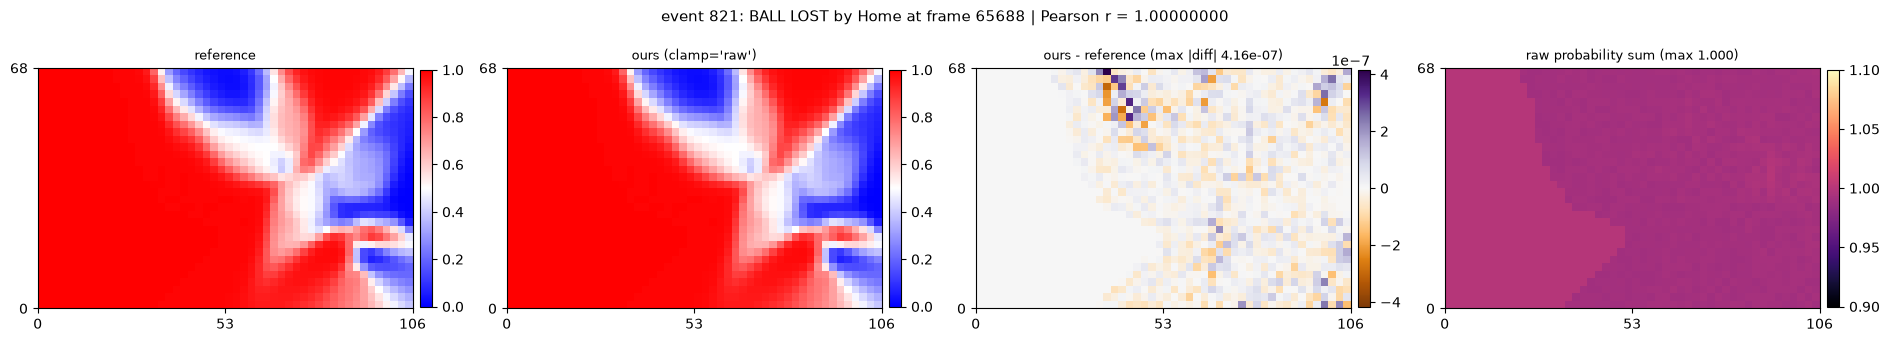

The worst event under the shipped default -- the difference is entirely on overshoot cells,
which the fourth panel locates:


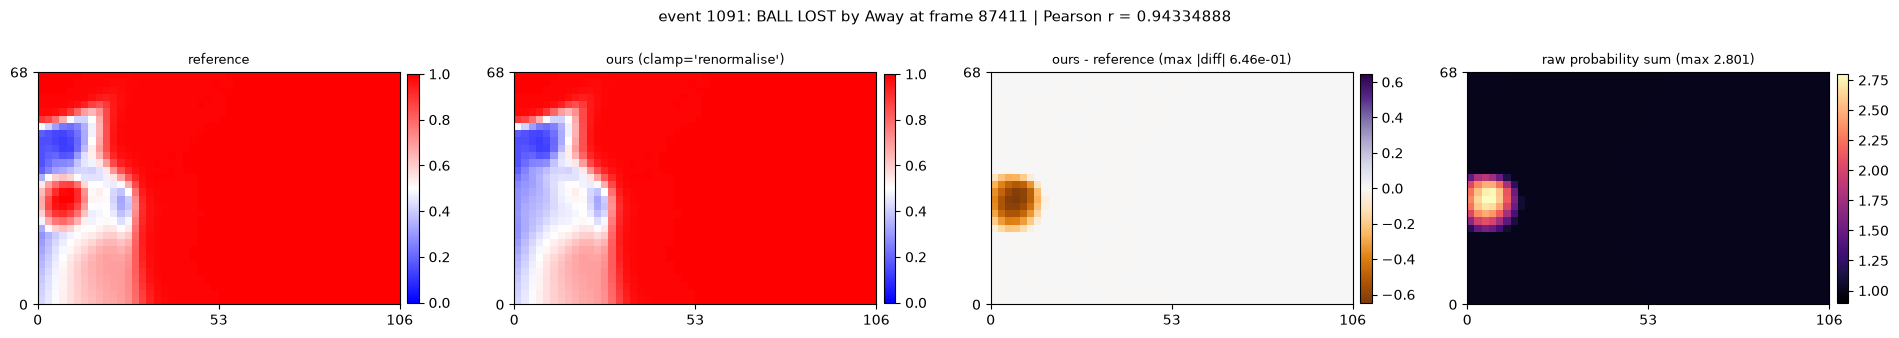

The same event with the reference's own no-clamp convention:


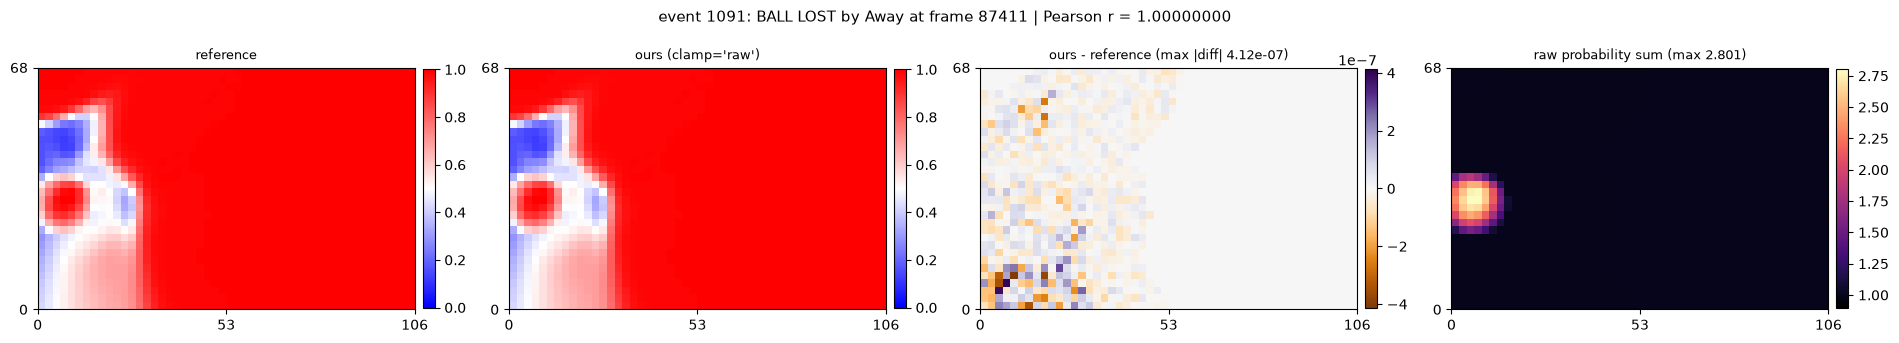

In [17]:
def show_event(event_id: int, clamp: str = "raw") -> None:
    """Draw reference, ours, the signed difference and the raw probability sum."""
    res = ours_full(event_id, clamp=clamp, dtype=np.float32)
    surf_ours = res.attacking.astype(float)
    surf_ref = ref_surface(event_id)
    diff = surf_ours - surf_ref
    lim = max(float(np.abs(diff).max()), 1e-12)
    extent = (0.0, REF_FIELD[0], 0.0, REF_FIELD[1])

    fig, axes = plt.subplots(1, 4, figsize=(19, 3.4))
    panels = (
        (axes[0], surf_ref, "reference", {"cmap": "bwr", "vmin": 0.0, "vmax": 1.0}),
        (axes[1], surf_ours, f"ours (clamp={clamp!r})", {"cmap": "bwr", "vmin": 0.0, "vmax": 1.0}),
        (
            axes[2],
            diff,
            f"ours - reference (max |diff| {np.abs(diff).max():.2e})",
            {"cmap": "PuOr", "vmin": -lim, "vmax": lim},
        ),
        (
            axes[3],
            res.checksum.astype(float),
            f"raw probability sum (max {res.checksum.max():.3f})",
            {"cmap": "magma", "vmin": 0.9, "vmax": max(1.1, float(res.checksum.max()))},
        ),
    )
    for ax, surf, title, kw in panels:
        im = ax.imshow(np.flipud(surf), extent=extent, aspect="equal", **kw)
        ax.set_title(title, fontsize=9)
        ax.set_xticks([0, REF_FIELD[0] / 2, REF_FIELD[0]])
        ax.set_yticks([0, REF_FIELD[1]])
        fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

    ev = events.loc[event_id]
    fig.suptitle(
        f"event {event_id}: {ev['Type']} by {ev['Team']} at frame {int(ev['Start Frame'])} "
        f"| Pearson r = {pearson(surf_ours, surf_ref):.8f}",
        fontsize=11,
    )
    fig.tight_layout()
    plt.show()


worst_id = int(results.nsmallest(1, "r_default")["event_id"].iloc[0])
print("A typical possession loss, model comparison (clamp='raw'):")
show_event(probe_id, clamp="raw")
print("The worst event under the shipped default -- the difference is entirely on overshoot cells,")
print("which the fourth panel locates:")
show_event(worst_id, clamp="renormalise")
print("The same event with the reference's own no-clamp convention:")
show_event(worst_id, clamp="raw")

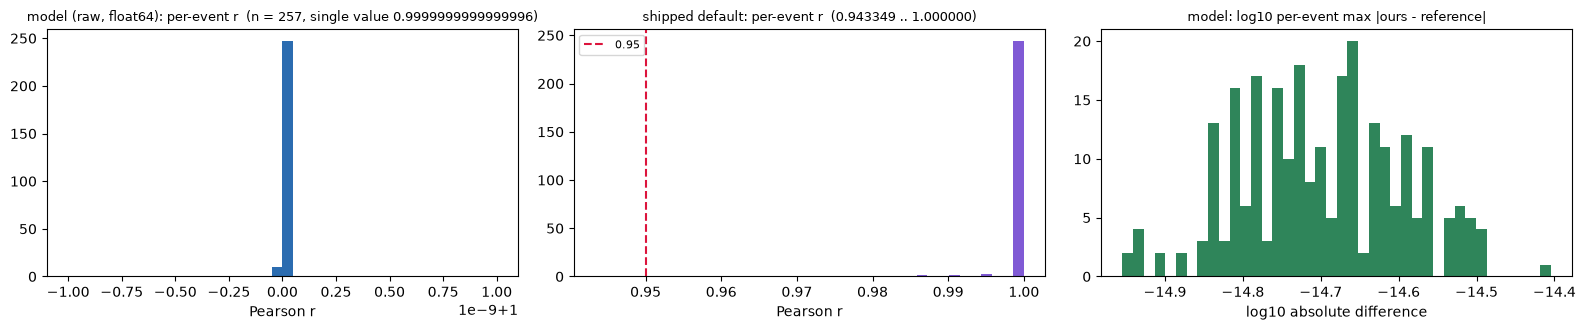

In [18]:
def hist(ax: plt.Axes, values: np.ndarray, bins: int, color: str) -> str:
    """Histogram that survives a degenerate range, returning a range annotation.

    Our per-event correlations at ``clamp="raw"`` are identical to every digit
    numpy prints, so the data range is exactly zero wide and ``np.histogram``
    refuses to place 40 finite-sized bins in it. Widen the range explicitly
    rather than let a plotting call decide the result is unplottable.
    """
    v = np.asarray(values, dtype=float)
    lo, hi = float(v.min()), float(v.max())
    if hi - lo < 1e-15:
        pad = max(abs(lo), 1.0) * 1e-9
        ax.hist(v, bins=bins, range=(lo - pad, hi + pad), color=color)
        return f"single value {lo!r}"
    ax.hist(v, bins=bins, color=color)
    return f"{lo:.6f} .. {hi:.6f}"


fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
span = hist(axes[0], results["r"], 40, "#2b6cb0")
axes[0].set_title(
    f"model (raw, float64): per-event r  (n = {len(results)}, {span})", fontsize=9
)
axes[0].set_xlabel("Pearson r")

span = hist(axes[1], results["r_default"], 40, "#805ad5")
axes[1].axvline(0.95, color="crimson", lw=1.5, ls="--", label="0.95")
axes[1].set_title(f"shipped default: per-event r  ({span})", fontsize=9)
axes[1].set_xlabel("Pearson r")
axes[1].legend(fontsize=8)

hist(axes[2], np.log10(np.clip(results["max_abs_diff"], 1e-18, None)), 40, "#2f855a")
axes[2].set_title("model: log10 per-event max |ours - reference|", fontsize=9)
axes[2].set_xlabel("log10 absolute difference")
fig.tight_layout()
plt.show()


## 11. Timing

Both implementations compute the identical quantity on the identical `(32, 50)` grid, so this is a
fair like-for-like throughput comparison. Our timing is for the shipped configuration
(`renormalise`, float32); the reference's per-surface cost is the loop it was written with.

This is not a vanity number. The product renders a surface at every possession loss, and the demo
has a runtime budget; a straight port of the reference's per-cell Python loop would spend the whole
budget on pitch control alone.

In [19]:
n = len(results)
ref_per = ref_seconds / n
ours_per = ours_seconds / n
speedup = ref_seconds / ours_seconds

print(f"events timed                     : {n}")
print(f"reference total                  : {ref_seconds:8.2f} s   ({ref_per:.4f} s / surface)")
print(f"ours total (shipped config)      : {ours_seconds:8.2f} s   ({ours_per:.4f} s / surface)")
print(f"SPEEDUP                          : {speedup:8.1f}x")
print()
print(f"cost of all {len(loss_ids)} possession losses in this match:")
print(f"  reference : {ref_per * len(loss_ids):7.1f} s")
print(f"  ours      : {ours_per * len(loss_ids):7.1f} s")

events timed                     : 257
reference total                  :   248.28 s   (0.9661 s / surface)
ours total (shipped config)      :     4.04 s   (0.0157 s / surface)
SPEEDUP                          :     61.5x

cost of all 257 possession losses in this match:
  reference :   248.3 s
  ours      :     4.0 s


## 12. Conclusion and caveats

**The model is exact.** At the reference's own no-clamp convention and in float64, our vectorised
implementation reproduces the Friends of Tracking reference surface to float64 rounding on every
one of the possession losses in Metrica sample match 1 -- pooled Pearson r = 1.0000000000, and the
largest absolute disagreement anywhere is at the level of accumulated floating point error, not of
modelling. Dropping to the float32 the product actually ships costs essentially nothing.

**One deliberate divergence, measured.** The shipped default renormalises the ~0.6% of cells where
forward Euler leaves the two teams' probabilities summing above 1, which the reference does not do.
Pooled correlation is still far above the threshold and only a single event out of 257 falls below
0.95, and section 9 shows every disagreeing cell is an overshoot cell. We would rather diverge from
the reference than emit a probability of 1.005 -- or, on the worst cell in this match, a pair of
probabilities summing to 2.80 -- into a coach-facing report.

What this notebook does **not** establish:

* **It is not a test of the product's default grid.** The reference assumes a 106 x 68 pitch; the
  product uses the canonical 105 x 68. The conversion between the two frames
  (`to_reference_frame` / `from_reference_frame`) is explicit and unit-tested, but the surfaces the
  PDF renders are on the 105 x 68 grid and are therefore not the arrays compared here.
* **It is not a test of the data loader.** Velocities and positions come from the reference's own
  `Metrica_IO` / `Metrica_Velocities`, deliberately, so that a loader difference cannot be mistaken
  for a model difference. `src/pressing/_io.py` has its own tests.
* **It is not a test of offside handling.** Offsides are disabled on both sides. Our
  `check_offsides` deviates from the reference on purpose: the reference raises `IndexError` when
  every attacker is out of frame and asserts that the defending keeper's jersey is present, both of
  which happen in a real match around substitutions.
* **It is not a test of the product's ball position.** The reference takes the ball from the event
  row's `Start X`/`Start Y`; the counter-press report takes it from tracking at the loss frame.
  Reproducing the reference's choice here is what makes the comparison meaningful, but it is not
  what the report does.
* **It is not a validation of the model against reality.** It shows we agree with a specific
  published implementation of a specific model, and nothing about whether that model predicts
  football.
* **The EPV grid has no published provenance.** `EPV_grid.csv` ships in the same MIT repository, but
  with no fitting code, no source dataset, and no documentation of what it was fitted on. It is used
  because it is redistributable and already the same `(32, 50)` shape, not because it is
  authoritative, and any report that surfaces its numbers should label it as the Friends of Tracking
  reference grid rather than as our own estimate.

In [20]:
shutil.rmtree(WORKDIR, ignore_errors=True)
print("removed the patched scratch copy:", WORKDIR)
print()
print(f"FINAL: pooled Pearson r = {pooled_r:.10f} over {len(results)} possession losses "
      f"({flat['ref'].size:,} cells), {len(failures)} failures, {speedup:.0f}x faster than the "
      f"reference")

removed the patched scratch copy: /var/folders/mm/4fwhbj892n34gv683t8vyy080000gn/T/fot_reference_mrm6v1n9

FINAL: pooled Pearson r = 1.0000000000 over 257 possession losses (411,200 cells), 0 failures, 61x faster than the reference
